[BTCUSDT] 3220 nến | 2018-01-01 -> 2026-10-25 | trùng: 0 | thiếu ngày: 0 | OHLC sai: 0 | NaN: 0 | volume<=0: 0
[BTCUSDT] train 2239 (2018-01-21→2024-03-08) | val 480 | test 480 (2025-07-02→2026-10-24)
[ETHUSDT] 3220 nến | 2018-01-01 -> 2026-10-25 | trùng: 0 | thiếu ngày: 0 | OHLC sai: 0 | NaN: 0 | volume<=0: 0
[ETHUSDT] train 2239 (2018-01-21→2024-03-08) | val 480 | test 480 (2025-07-02→2026-10-24)

=== KẾT QUẢ TRÊN TẬP TEST ===


,symbol,model,MAE,RMSE,DirAcc
0,BTCUSDT,Baseline: return=0,0.01520,0.02173,0.51250
1,BTCUSDT,Baseline: mean return (train),0.01530,0.02180,0.48750
2,BTCUSDT,Baseline: luôn đoán tăng,NaN,NaN,0.48750
3,BTCUSDT,XGBoost (best_iter=3),0.01529,0.02178,0.48958
4,ETHUSDT,Baseline: return=0,0.02287,0.03323,0.48542
5,ETHUSDT,Baseline: mean return (train),0.02290,0.03326,0.51458
6,ETHUSDT,Baseline: luôn đoán tăng,NaN,NaN,0.51458
7,ETHUSDT,XGBoost (best_iter=49),0.02293,0.03315,0.52083


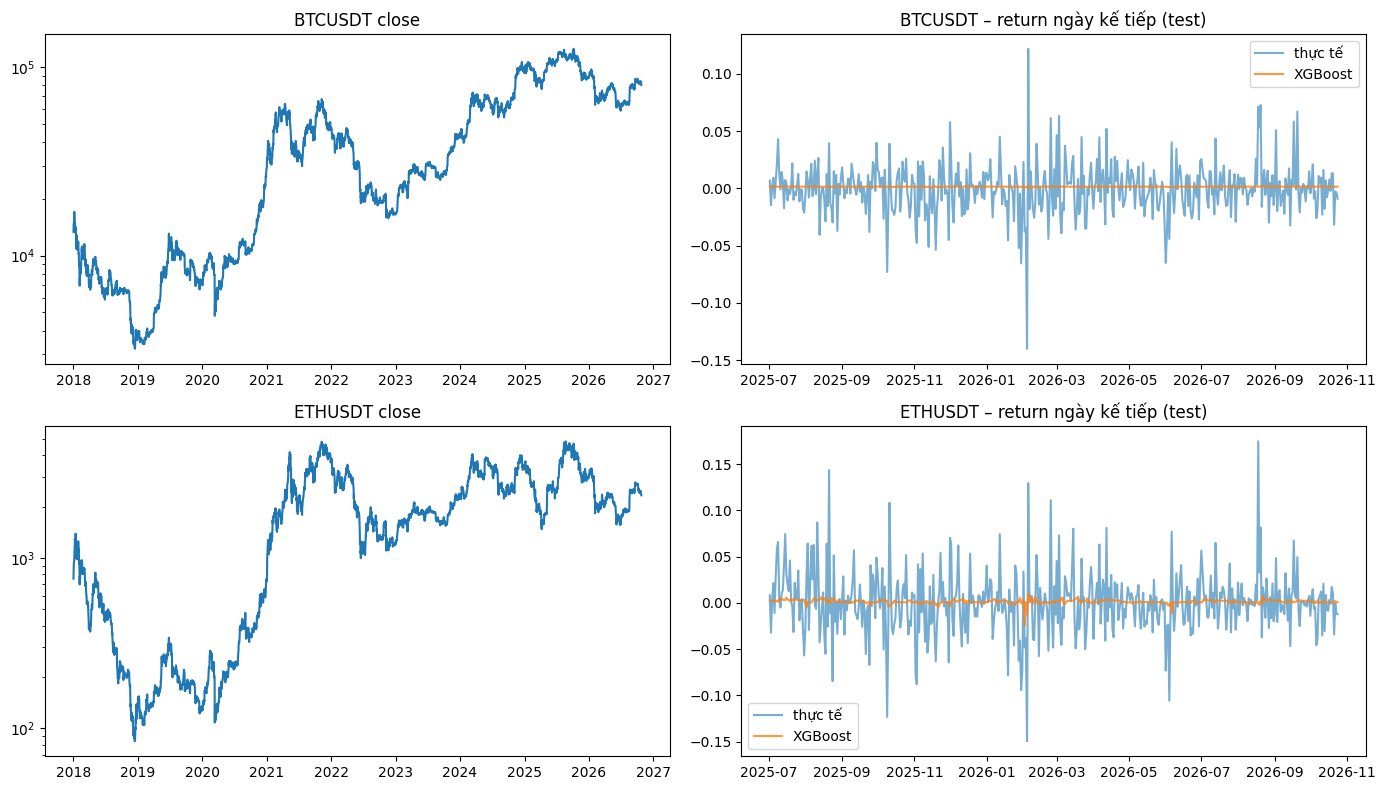

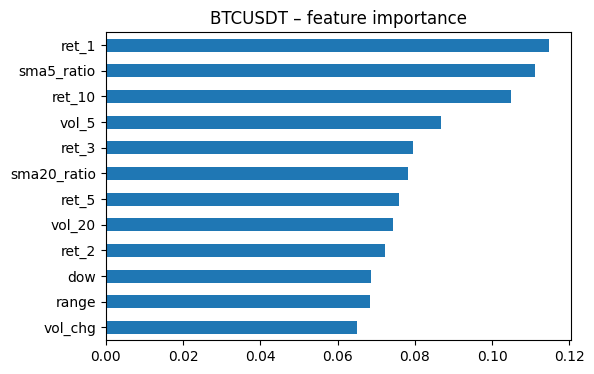

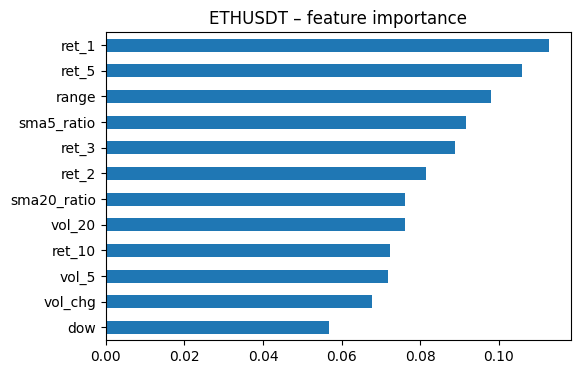

In [ ]:
# ===== CELL 1: Tải dữ liệu + baseline + XGBoost (target = return ngày mai) =====
!pip -q install xgboost

import time, json, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ============ 1. CẤU HÌNH ============
# Dùng mirror dữ liệu công khai (api.binance.com hay bị chặn IP trên Colab/US)
BASE_URL = "https://data-api.binance.vision/api/v3/klines"
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
START = "2018-01-01"
SEED = 42

# ============ 2. TẢI DỮ LIỆU ============
def fetch_klines(symbol, interval="1d", start=START):
    start_ms = int(pd.Timestamp(start, tz="UTC").timestamp() * 1000)
    rows = []
    while True:
        r = requests.get(BASE_URL, params=dict(symbol=symbol, interval=interval,
                                               startTime=start_ms, limit=1000), timeout=30)
        r.raise_for_status()
        data = r.json()
        if not data:
            break
        rows += data
        start_ms = data[-1][0] + 1
        if len(data) < 1000:
            break
        time.sleep(0.2)
    cols = ["open_time", "open", "high", "low", "close", "volume", "close_time",
            "quote_volume", "trades", "tb_base", "tb_quote", "ignore"]
    df = pd.DataFrame(rows, columns=cols)
    df["date"] = pd.to_datetime(df["open_time"], unit="ms")  # UTC
    for c in ["open", "high", "low", "close", "volume"]:
        df[c] = df[c].astype(float)
    # bỏ nến chưa đóng
    df = df[df["close_time"] < int(time.time() * 1000)]
    df = df[["date", "open", "high", "low", "close", "volume"]]
    return df.drop_duplicates("date").sort_values("date").reset_index(drop=True)

# ============ 3. KIỂM TRA CHẤT LƯỢNG ============
def validate(df, name):
    gaps = df["date"].diff().dropna()
    bad_hl = ((df["high"] < df[["open", "close", "low"]].max(axis=1)) |
              (df["low"] > df[["open", "close", "high"]].min(axis=1))).sum()
    print(f"[{name}] {len(df)} nến | {df['date'].min().date()} -> {df['date'].max().date()} | "
          f"trùng: {df['date'].duplicated().sum()} | thiếu ngày: {(gaps > pd.Timedelta(days=1)).sum()} | "
          f"OHLC sai: {bad_hl} | NaN: {df.isna().sum().sum()} | volume<=0: {(df['volume'] <= 0).sum()}")

# ============ 4. FEATURE + TARGET ============
def make_features(df):
    d = df.copy()
    d["ret_1"] = d["close"].pct_change()
    for k in [2, 3, 5, 10]:
        d[f"ret_{k}"] = d["close"].pct_change(k)
    d["vol_5"] = d["ret_1"].rolling(5).std()
    d["vol_20"] = d["ret_1"].rolling(20).std()
    d["sma5_ratio"] = d["close"] / d["close"].rolling(5).mean() - 1
    d["sma20_ratio"] = d["close"] / d["close"].rolling(20).mean() - 1
    d["range"] = (d["high"] - d["low"]) / d["close"]
    d["vol_chg"] = np.log(d["volume"]).diff()
    d["dow"] = d["date"].dt.dayofweek
    # Target: return của ngày kế tiếp (chỉ biết sau khi ngày t+1 đóng nến)
    d["target"] = d["close"].shift(-1) / d["close"] - 1
    return d

FEATURES = ["ret_1", "ret_2", "ret_3", "ret_5", "ret_10", "vol_5", "vol_20",
            "sma5_ratio", "sma20_ratio", "range", "vol_chg", "dow"]

# ============ 5. ĐÁNH GIÁ ============
def metrics(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": float(np.sqrt(mean_squared_error(y, pred))),
            "DirAcc": float(((pred > 0) == (y > 0)).mean())}

# ============ 6. CHẠY CHO TỪNG COIN ============
results, models = [], {}
for sym in SYMBOLS:
    raw = fetch_klines(sym)
    validate(raw, sym)
    raw.to_csv(f"{sym}_1d_raw.csv", index=False)

    d = make_features(raw)
    d.to_csv(f"{sym}_1d_features.csv", index=False)
    d = d.dropna(subset=FEATURES + ["target"]).reset_index(drop=True)  # dòng cuối (chưa có target) bị loại

    # chia THEO THỜI GIAN: 70% train / 15% val / 15% test
    n = len(d); i1, i2 = int(n * 0.70), int(n * 0.85)
    tr, va, te = d.iloc[:i1], d.iloc[i1:i2], d.iloc[i2:]
    print(f"[{sym}] train {len(tr)} ({tr.date.min().date()}→{tr.date.max().date()}) | "
          f"val {len(va)} | test {len(te)} ({te.date.min().date()}→{te.date.max().date()})")

    # --- Baseline 1: return = 0 (persistence giá) ---
    results.append({"symbol": sym, "model": "Baseline: return=0",
                    **metrics(te["target"], np.zeros(len(te)))})
    # --- Baseline 2: luôn đoán tăng bằng return TB của train (cho DirAcc theo lớp đa số) ---
    mean_ret = tr["target"].mean()
    results.append({"symbol": sym, "model": "Baseline: mean return (train)",
                    **metrics(te["target"], np.full(len(te), mean_ret))})
    results.append({"symbol": sym, "model": "Baseline: luôn đoán tăng",
                    "MAE": np.nan, "RMSE": np.nan,
                    "DirAcc": float((te["target"] > 0).mean())})

    # --- XGBoost (early stopping trên validation, KHÔNG nhìn test) ---
    xgb = XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=3,
                       subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                       reg_lambda=1.0, early_stopping_rounds=50,
                       random_state=SEED, n_jobs=-1)
    xgb.fit(tr[FEATURES], tr["target"], eval_set=[(va[FEATURES], va["target"])], verbose=False)
    pred = xgb.predict(te[FEATURES])
    results.append({"symbol": sym, "model": f"XGBoost (best_iter={xgb.best_iteration})",
                    **metrics(te["target"], pred)})

    xgb.save_model(f"{sym}_xgb_v1.json")
    models[sym] = (xgb, te.assign(pred=pred))

res = pd.DataFrame(results)
res.to_csv("results_v1.csv", index=False)
pd.set_option("display.float_format", lambda x: f"{x:.5f}")
print("\n=== KẾT QUẢ TRÊN TẬP TEST ===")
display(res)

# ============ 7. BIỂU ĐỒ ============
fig, ax = plt.subplots(len(SYMBOLS), 2, figsize=(14, 4 * len(SYMBOLS)))
for i, sym in enumerate(SYMBOLS):
    xgb, t = models[sym]
    raw = pd.read_csv(f"{sym}_1d_raw.csv", parse_dates=["date"])
    ax[i, 0].plot(raw["date"], raw["close"]); ax[i, 0].set_title(f"{sym} close"); ax[i, 0].set_yscale("log")
    ax[i, 1].plot(t["date"], t["target"], label="thực tế", alpha=.6)
    ax[i, 1].plot(t["date"], t["pred"], label="XGBoost", alpha=.8)
    ax[i, 1].set_title(f"{sym} – return ngày kế tiếp (test)"); ax[i, 1].legend()
plt.tight_layout(); plt.show()

# Feature importance
for sym in SYMBOLS:
    s = pd.Series(models[sym][0].feature_importances_, index=FEATURES).sort_values()
    s.plot.barh(title=f"{sym} – feature importance", figsize=(6, 4)); plt.show()

In [ ]:
# ===== CELL 2: Biến động ngày mai (biên độ nến) + walk-forward | cần chạy Cell 1 trước =====
import numpy as np, pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

SYMBOLS = ["BTCUSDT", "ETHUSDT"]
SEED = 42
FEATS = ["range", "range_l1", "range_l2", "range_l3", "range_ma5", "range_ma20",
         "abs_ret", "abs_ret_ma5", "ret_1", "ret_5", "vol_5", "vol_20", "vol_chg", "dow"]

def make_vol_data(sym):
    d = pd.read_csv(f"{sym}_1d_raw.csv", parse_dates=["date"])
    d["ret_1"] = d["close"].pct_change()
    d["abs_ret"] = d["ret_1"].abs()
    d["range"] = (d["high"] - d["low"]) / d["close"]
    for k in [1, 2, 3]:
        d[f"range_l{k}"] = d["range"].shift(k)
    d["range_ma5"] = d["range"].rolling(5).mean()
    d["range_ma20"] = d["range"].rolling(20).mean()
    d["abs_ret_ma5"] = d["abs_ret"].rolling(5).mean()
    d["ret_5"] = d["close"].pct_change(5)
    d["vol_5"] = d["ret_1"].rolling(5).std()
    d["vol_20"] = d["ret_1"].rolling(20).std()
    d["vol_chg"] = np.log(d["volume"]).diff()
    d["dow"] = d["date"].dt.dayofweek
    d["target"] = d["range"].shift(-1)          # biên độ nến ngày kế tiếp
    return d.dropna(subset=FEATS + ["target"]).reset_index(drop=True)

def ev(y, p):
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "R2": r2_score(y, p)}

def new_xgb(**kw):
    return XGBRegressor(learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                        min_child_weight=5, random_state=SEED, n_jobs=-1, **kw)

rows, models = [], {}
for sym in SYMBOLS:
    d = make_vol_data(sym)
    n = len(d); i1, i2 = int(n * 0.70), int(n * 0.85)
    tr, va, te = d.iloc[:i1], d.iloc[i1:i2], d.iloc[i2:]

    # --- Baselines ---
    rows.append({"symbol": sym, "model": "Baseline: = hôm nay", **ev(te["target"], te["range"])})
    rows.append({"symbol": sym, "model": "Baseline: TB 5 ngày", **ev(te["target"], te["range_ma5"])})
    rows.append({"symbol": sym, "model": "Baseline: TB 20 ngày", **ev(te["target"], te["range_ma20"])})

    # --- XGBoost: học log(target), early stopping trên validation ---
    m = new_xgb(n_estimators=2000, early_stopping_rounds=100)
    m.fit(tr[FEATS], np.log(tr["target"]), eval_set=[(va[FEATS], np.log(va["target"]))], verbose=False)
    pred = np.exp(m.predict(te[FEATS]))
    rows.append({"symbol": sym, "model": f"XGBoost (best_iter={m.best_iteration})", **ev(te["target"], pred)})
    m.save_model(f"{sym}_xgb_vol_v1.json")
    models[sym] = te.assign(pred=pred)
    te.assign(pred=pred)[["date", "target", "pred"]].to_csv(f"{sym}_vol_test_pred.csv", index=False)

res = pd.DataFrame(rows)
# % MAE cải thiện so với baseline TB5 ngày (mạnh nhất trong 3 baseline thường dùng)
ref = res[res.model == "Baseline: TB 5 ngày"].set_index("symbol")["MAE"]
res["MAE_vs_MA5_%"] = [(1 - r.MAE / ref[r.symbol]) * 100 for r in res.itertuples()]
res.to_csv("results_vol_v1.csv", index=False)
pd.set_option("display.float_format", lambda x: f"{x:.5f}")
print("=== BIẾN ĐỘNG NGÀY KẾ TIẾP – TẬP TEST ===")
display(res)

# ============ WALK-FORWARD: 5 fold, mỗi fold test 180 ngày ============
print("\n=== WALK-FORWARD (expanding window, 5 fold x 180 ngày) ===")
wf_rows = []
for sym in SYMBOLS:
    d = make_vol_data(sym)
    tscv = TimeSeriesSplit(n_splits=5, test_size=180)
    for k, (a, b) in enumerate(tscv.split(d), 1):
        tr, te = d.iloc[a], d.iloc[b]
        m = new_xgb(n_estimators=300)                       # cố định, không nhìn test
        m.fit(tr[FEATS], np.log(tr["target"]))
        p = np.exp(m.predict(te[FEATS]))
        wf_rows.append({"symbol": sym, "fold": k, "test_from": te.date.min().date(),
                        "MAE_xgb": mean_absolute_error(te["target"], p),
                        "MAE_ma5": mean_absolute_error(te["target"], te["range_ma5"]),
                        "MAE_today": mean_absolute_error(te["target"], te["range"])})
wf = pd.DataFrame(wf_rows)
wf["gain_vs_ma5_%"] = (1 - wf["MAE_xgb"] / wf["MAE_ma5"]) * 100
wf.to_csv("walkforward_vol_v1.csv", index=False)
display(wf)
print(wf.groupby("symbol")[["MAE_xgb", "MAE_ma5", "MAE_today", "gain_vs_ma5_%"]].mean())
print("Số fold XGBoost thắng TB5:", (wf["MAE_xgb"] < wf["MAE_ma5"]).groupby(wf["symbol"]).sum().to_dict(), "/ 5")

=== BIẾN ĐỘNG NGÀY KẾ TIẾP – TẬP TEST ===


,symbol,model,MAE,RMSE,R2,MAE_vs_MA5_%
0,BTCUSDT,Baseline: = hôm nay,0.01564,0.02247,-0.24682,-16.71739
1,BTCUSDT,Baseline: TB 5 ngày,0.01340,0.01956,0.05469,0.00000
2,BTCUSDT,Baseline: TB 20 ngày,0.01318,0.01976,0.03602,1.62135
3,BTCUSDT,XGBoost (best_iter=287),0.01086,0.01692,0.29283,18.97680
4,ETHUSDT,Baseline: = hôm nay,0.02378,0.03413,-0.36336,-21.76687
5,ETHUSDT,Baseline: TB 5 ngày,0.01953,0.02861,0.04212,0.00000
6,ETHUSDT,Baseline: TB 20 ngày,0.01992,0.02895,0.01891,-2.00262
7,ETHUSDT,XGBoost (best_iter=232),0.01669,0.02580,0.22110,14.53286



=== WALK-FORWARD (expanding window, 5 fold x 180 ngày) ===


,symbol,fold,test_from,MAE_xgb,MAE_ma5,MAE_today,gain_vs_ma5_%
0,BTCUSDT,1,2024-05-08,0.01272,0.01582,0.01904,19.59304
1,BTCUSDT,2,2024-11-04,0.01503,0.01865,0.02013,19.40082
2,BTCUSDT,3,2025-05-03,0.01009,0.01180,0.01457,14.49671
3,BTCUSDT,4,2025-10-30,0.01217,0.01564,0.01829,22.16264
4,BTCUSDT,5,2026-04-28,0.00931,0.01250,0.01354,25.51346
5,ETHUSDT,1,2024-05-08,0.01694,0.01946,0.02370,12.92112
6,ETHUSDT,2,2024-11-04,0.02306,0.02813,0.02833,18.01797
7,ETHUSDT,3,2025-05-03,0.01805,0.02198,0.02664,17.87436
8,ETHUSDT,4,2025-10-30,0.01946,0.02244,0.02736,13.28637
9,ETHUSDT,5,2026-04-28,0.01334,0.01635,0.01845,18.36883


         MAE_xgb  MAE_ma5  MAE_today  gain_vs_ma5_%
symbol                                             
BTCUSDT  0.01187  0.01488    0.01711       20.23333
ETHUSDT  0.01817  0.02167    0.02489       16.09373
Số fold XGBoost thắng TB5: {'BTCUSDT': 5, 'ETHUSDT': 5} / 5


In [ ]:
# ===== CELL 3: So sánh cách xử lý log (gốc vs log+exp vs log+smearing), walk-forward 5 fold =====
# Cần chạy Cell 2 trước (dùng lại make_vol_data, new_xgb, FEATS, SYMBOLS)
import numpy as np, pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

def row(sym, fold, name, y, p):
    return {"symbol": sym, "fold": fold, "model": name,
            "MAE": mean_absolute_error(y, p),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "bias_%": (np.mean(p) / np.mean(y) - 1) * 100}   # <0: dự đoán thấp hơn thực tế

out = []
for sym in SYMBOLS:
    d = make_vol_data(sym)
    for k, (a, b) in enumerate(TimeSeriesSplit(n_splits=5, test_size=180).split(d), 1):
        tr, te = d.iloc[a], d.iloc[b]
        y = te["target"]

        # Baselines
        out.append(row(sym, k, "Baseline: = hôm nay", y, te["range"]))
        out.append(row(sym, k, "Baseline: TB 5 ngày", y, te["range_ma5"]))
        out.append(row(sym, k, "Baseline: TB 20 ngày", y, te["range_ma20"]))

        # A) target gốc
        mA = new_xgb(n_estimators=300).fit(tr[FEATS], tr["target"])
        out.append(row(sym, k, "XGB: target gốc", y, np.clip(mA.predict(te[FEATS]), 1e-6, None)))

        # B) log + exp
        mB = new_xgb(n_estimators=300).fit(tr[FEATS], np.log(tr["target"]))
        out.append(row(sym, k, "XGB: log + exp", y, np.exp(mB.predict(te[FEATS]))))

        # C) log + exp + smearing (Duan): nhân hệ số = mean(exp(phần dư train))
        smear = np.mean(np.exp(np.log(tr["target"]) - mB.predict(tr[FEATS])))
        out.append(row(sym, k, "XGB: log + smearing", y, np.exp(mB.predict(te[FEATS])) * smear))

long = pd.DataFrame(out)
long.to_csv("walkforward_vol_compare_v1.csv", index=False)
pd.set_option("display.float_format", lambda x: f"{x:.5f}")

print("=== TRUNG BÌNH 5 FOLD ===")
summary = long.groupby(["symbol", "model"])[["MAE", "RMSE", "bias_%"]].mean()
display(summary)

print("\n=== SỐ FOLD THẮNG BASELINE 'TB 5 NGÀY' (theo MAE / theo RMSE), tối đa 5 ===")
for metric in ["MAE", "RMSE"]:
    piv = long.pivot_table(index=["symbol", "fold"], columns="model", values=metric)
    wins = pd.DataFrame({c: (piv[c] < piv["Baseline: TB 5 ngày"]).groupby(level=0).sum()
                         for c in piv.columns if c.startswith("XGB")})
    print(f"\n-- {metric} --"); display(wins)

print("\n=== CHI TIẾT TỪNG FOLD (MAE) ===")
display(long.pivot_table(index=["symbol", "fold"], columns="model", values="MAE"))

=== TRUNG BÌNH 5 FOLD ===


MAE    RMSE   bias_%
symbol  model                                        
BTCUSDT Baseline: = hôm nay  0.01711 0.02371  0.01561
        Baseline: TB 20 ngày 0.01470 0.02062  0.48208
        Baseline: TB 5 ngày  0.01488 0.02063  0.03915
        XGB: log + exp       0.01187 0.01756 -6.17444
        XGB: log + smearing  0.01239 0.01749  3.33047
        XGB: target gốc      0.01315 0.01789 10.41962
ETHUSDT Baseline: = hôm nay  0.02489 0.03570 -0.00671
        Baseline: TB 20 ngày 0.02200 0.03154  0.16233
        Baseline: TB 5 ngày  0.02167 0.03132  0.00544
        XGB: log + exp       0.01817 0.02786 -6.81568
        XGB: log + smearing  0.01904 0.02773  1.96293
        XGB: target gốc      0.01978 0.02822  5.69551


=== SỐ FOLD THẮNG BASELINE 'TB 5 NGÀY' (theo MAE / theo RMSE), tối đa 5 ===

-- MAE --


,XGB: log + exp,XGB: log + smearing,XGB: target gốc
symbol,,,
BTCUSDT,5,5,4
ETHUSDT,5,5,5



-- RMSE --


,XGB: log + exp,XGB: log + smearing,XGB: target gốc
symbol,,,
BTCUSDT,5,5,5
ETHUSDT,5,5,5



=== CHI TIẾT TỪNG FOLD (MAE) ===


model         Baseline: = hôm nay  Baseline: TB 20 ngày  Baseline: TB 5 ngày  \
symbol  fold                                                                   
BTCUSDT 1                 0.01904               0.01477              0.01582   
        2                 0.02013               0.01970              0.01865   
        3                 0.01457               0.01097              0.01180   
        4                 0.01829               0.01646              0.01564   
        5                 0.01354               0.01157              0.01250   
ETHUSDT 1                 0.02370               0.01915              0.01946   
        2                 0.02833               0.02901              0.02813   
        3                 0.02664               0.02164              0.02198   
        4                 0.02736               0.02454              0.02244   
        5                 0.01845               0.01567              0.01635   

model         XGB: log + exp  XGB: log + smearing  XGB: target gốc  
symbol  fold                                                        
BTCUSDT 1            0.01272              0.01299          0.01382  
        2            0.01503              0.01556          0.01593  
        3            0.01009              0.01066          0.01193  
        4            0.01217              0.01281          0.01331  
        5            0.00931              0.00994          0.01078  
ETHUSDT 1            0.01694              0.01791          0.01865  
        2            0.02306              0.02382          0.02478  
        3            0.01805              0.01886          0.01945  
        4            0.01946              0.02014          0.02053  
        5            0.01334              0.01448          0.01546

In [ ]:
# ===== CELL 4: Huấn luyện bản cuối + tạo thư mục artifacts cho Streamlit | cần chạy Cell 1 + Cell 2 trước =====
import os, json, shutil, datetime as dt
import numpy as np, pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

VERSION, N_EST = "vol_v1", 300
os.makedirs("artifacts", exist_ok=True)

def build(raw):
    """Feature + target (target = biên độ nến NGÀY KẾ TIẾP). Dòng cuối có target=NaN -> dùng để dự đoán ngày mai."""
    d = raw.copy()
    d["ret_1"] = d["close"].pct_change()
    d["abs_ret"] = d["ret_1"].abs()
    d["range"] = (d["high"] - d["low"]) / d["close"]
    for k in [1, 2, 3]:
        d[f"range_l{k}"] = d["range"].shift(k)
    d["range_ma5"] = d["range"].rolling(5).mean()
    d["range_ma20"] = d["range"].rolling(20).mean()
    d["abs_ret_ma5"] = d["abs_ret"].rolling(5).mean()
    d["ret_5"] = d["close"].pct_change(5)
    d["vol_5"] = d["ret_1"].rolling(5).std()
    d["vol_20"] = d["ret_1"].rolling(20).std()
    d["vol_chg"] = np.log(d["volume"]).diff()
    d["dow"] = d["date"].dt.dayofweek
    d["target"] = d["range"].shift(-1)
    return d

def fit_smear(tr):
    """XGBoost học log(target); hệ số smearing (Duan) sửa bias khi exp() ngược về thang gốc."""
    m = new_xgb(n_estimators=N_EST).fit(tr[FEATS], np.log(tr["target"]))
    smear = float(np.mean(np.exp(np.log(tr["target"]) - m.predict(tr[FEATS]))))
    return m, smear

def mae(a, b): return mean_absolute_error(a, b)
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))

metrics_rows, fold_rows, forecasts = [], [], {}
for sym in SYMBOLS:
    raw = fetch_klines(sym)                                   # tải lại để có nến đóng cửa mới nhất
    raw.to_csv(f"artifacts/{sym}_1d_raw.csv", index=False)
    d = build(raw)
    lab = d.dropna(subset=FEATS + ["target"]).reset_index(drop=True)

    # 1) Walk-forward out-of-sample: expanding window, 5 fold x 180 ngày, gap=1 (tránh chồng lấn target)
    parts = []
    for k, (a, b) in enumerate(TimeSeriesSplit(n_splits=5, test_size=180, gap=1).split(lab), 1):
        tr, te = lab.iloc[a], lab.iloc[b]
        m, s = fit_smear(tr)
        parts.append(pd.DataFrame({
            "fold": k,
            "date": (te["date"] + pd.Timedelta(days=1)).values,    # ngày được dự đoán
            "actual": te["target"].values,
            "pred": np.exp(m.predict(te[FEATS])) * s,
            "ma5": te["range_ma5"].values,
            "ma20": te["range_ma20"].values,
            "today": te["range"].values}))
    oos = pd.concat(parts, ignore_index=True)
    oos.to_csv(f"artifacts/{sym}_oos_pred.csv", index=False)

    # 2) Metrics gộp toàn bộ OOS + theo từng fold
    y = oos["actual"]
    for name, col in [("XGBoost (log + smearing)", "pred"), ("Baseline: TB 5 ngày", "ma5"),
                      ("Baseline: TB 20 ngày", "ma20"), ("Baseline: = hôm nay", "today")]:
        metrics_rows.append({"symbol": sym, "model": name, "MAE": mae(y, oos[col]),
                             "RMSE": rmse(y, oos[col]), "bias_%": (oos[col].mean() / y.mean() - 1) * 100})
    for k, g in oos.groupby("fold"):
        fold_rows.append({"symbol": sym, "fold": int(k), "from": str(g["date"].min().date()),
                          "to": str(g["date"].max().date()),
                          "MAE_xgb": mae(g["actual"], g["pred"]), "MAE_ma5": mae(g["actual"], g["ma5"]),
                          "RMSE_xgb": rmse(g["actual"], g["pred"]), "RMSE_ma5": rmse(g["actual"], g["ma5"])})

    # 3) Khoảng bất định THỰC NGHIỆM: phân vị 10%-90% của (thực tế / dự đoán) trên OOS
    ratio = oos["actual"] / oos["pred"]
    q10, q90 = float(ratio.quantile(0.10)), float(ratio.quantile(0.90))

    # 4) Mô hình cuối: huấn luyện trên TOÀN BỘ dữ liệu có nhãn, dự đoán biên độ ngày mai
    m, s = fit_smear(lab)
    m.save_model(f"artifacts/{sym}_{VERSION}.json")
    last = d.dropna(subset=FEATS).iloc[[-1]]                   # nến đã đóng cửa mới nhất
    pred = float(np.exp(m.predict(last[FEATS]))[0] * s)
    last_date = last["date"].iloc[0]
    forecasts[sym] = {"last_candle_date": str(last_date.date()),
                      "forecast_for_date": str((last_date + pd.Timedelta(days=1)).date()),
                      "last_close": float(last["close"].iloc[0]),
                      "pred_range": pred, "band_low": pred * q10, "band_high": pred * q90,
                      "q10": q10, "q90": q90, "smear": s, "n_train": int(len(lab)),
                      "model_version": VERSION}

metrics = pd.DataFrame(metrics_rows); folds = pd.DataFrame(fold_rows)
metrics.to_csv("artifacts/metrics.csv", index=False)
folds.to_csv("artifacts/folds.csv", index=False)
with open("artifacts/forecast.json", "w", encoding="utf-8") as f:
    json.dump(forecasts, f, ensure_ascii=False, indent=2)
with open("artifacts/meta.json", "w", encoding="utf-8") as f:
    json.dump({"generated_at_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
               "model_version": VERSION, "features": FEATS, "n_estimators": N_EST,
               "target": "range_{t+1} = (high-low)/close của nến ngày kế tiếp",
               "validation": "walk-forward expanding window, 5 fold x 180 ngày, gap=1"},
              f, ensure_ascii=False, indent=2)

pd.set_option("display.float_format", lambda x: f"{x:.5f}")
print("=== METRICS OOS (gộp 5 fold) ===");  print(metrics.to_string(index=False))
print("\n=== TỪNG FOLD ===");               print(folds.to_string(index=False))
print("\n=== DỰ ĐOÁN NGÀY MAI ===")
print(pd.DataFrame(forecasts).T[["last_candle_date", "forecast_for_date", "last_close",
                                 "pred_range", "band_low", "band_high"]].to_string())

# Nén để tải về máy (Colab)
try:
    shutil.make_archive("artifacts", "zip", "artifacts")
    from google.colab import files
    files.download("artifacts.zip")
except Exception as e:
    print("\n(Bỏ qua tải zip tự động:", type(e).__name__, ")")

=== METRICS OOS (gộp 5 fold) ===
 symbol                    model     MAE    RMSE  bias_%
BTCUSDT XGBoost (log + smearing) 0.01238 0.01772 2.72621
BTCUSDT      Baseline: TB 5 ngày 0.01488 0.02084 0.12312
BTCUSDT     Baseline: TB 20 ngày 0.01470 0.02095 0.62365
BTCUSDT      Baseline: = hôm nay 0.01711 0.02388 0.06386
ETHUSDT XGBoost (log + smearing) 0.01902 0.02805 1.46929
ETHUSDT      Baseline: TB 5 ngày 0.02167 0.03170 0.02826
ETHUSDT     Baseline: TB 20 ngày 0.02200 0.03202 0.17672
ETHUSDT      Baseline: = hôm nay 0.02489 0.03595 0.01553

=== TỪNG FOLD ===
 symbol  fold       from         to  MAE_xgb  MAE_ma5  RMSE_xgb  RMSE_ma5
BTCUSDT     1 2024-05-09 2024-11-04  0.01311  0.01582   0.01820   0.02157
BTCUSDT     2 2024-11-05 2025-05-03  0.01560  0.01865   0.02131   0.02457
BTCUSDT     3 2025-05-04 2025-10-30  0.01059  0.01180   0.01687   0.01820
BTCUSDT     4 2025-10-31 2026-04-28  0.01275  0.01564   0.01792   0.02240
BTCUSDT     5 2026-04-29 2026-10-25  0.00987  0.01250   0.01338  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ===== CELL 5: TỔ CHỨC DỰ ÁN TRONG GOOGLE DRIVE =====

import os
import shutil
import pandas as pd

# 1. Kết nối Google Drive nếu đang chạy trên Colab
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/crypto-volatility-prediction"
except ImportError:
    ROOT = "crypto-volatility-prediction"

# 2. Thư mục artifacts do Cell 4 tạo
SRC = "artifacts"

if not os.path.isdir(SRC):
    raise FileNotFoundError(
        "Không tìm thấy thư mục artifacts/. "
        "Hãy chạy Cell 4 trước khi chạy Cell 5."
    )

# 3. Tạo cấu trúc thư mục
for sub in ["notebooks", "data", "artifacts", "models"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)

# 4. Sao chép dữ liệu, mô hình và tổng hợp dự đoán
preds = []

for sym in SYMBOLS:
    raw_file = os.path.join(SRC, f"{sym}_1d_raw.csv")
    model_file = os.path.join(SRC, f"{sym}_{VERSION}.json")
    pred_file = os.path.join(SRC, f"{sym}_oos_pred.csv")

    for path in [raw_file, model_file, pred_file]:
        if not os.path.isfile(path):
            raise FileNotFoundError(f"Thiếu file: {path}")

    shutil.copy2(
        raw_file,
        os.path.join(ROOT, "data", f"{sym}.csv")
    )

    shutil.copy2(
        model_file,
        os.path.join(ROOT, "models", f"{sym}_model.json")
    )

    p = pd.read_csv(pred_file)
    p.insert(0, "symbol", sym)
    preds.append(p)

pd.concat(preds, ignore_index=True).to_csv(
    os.path.join(ROOT, "artifacts", "predictions.csv"),
    index=False
)

# 5. Sao chép báo cáo đánh giá và dự đoán
for filename in [
    "metrics.csv",
    "folds.csv",
    "forecast.json",
    "meta.json"
]:
    source = os.path.join(SRC, filename)

    if not os.path.isfile(source):
        raise FileNotFoundError(f"Thiếu file: {source}")

    shutil.copy2(
        source,
        os.path.join(ROOT, "artifacts", filename)
    )

print(f"Đã tạo/cập nhật dự án tại: {ROOT}")

for dp, _, files in sorted(os.walk(ROOT)):
    for filename in sorted(files):
        path = os.path.join(dp, filename)
        print(" ", os.path.relpath(path, ROOT))


Mounted at /content/drive
Đã tạo/cập nhật dự án tại: /content/drive/MyDrive/crypto-volatility-prediction
  artifacts/folds.csv
  artifacts/forecast.json
  artifacts/meta.json
  artifacts/metrics.csv
  artifacts/predictions.csv
  data/BTCUSDT.csv
  data/ETHUSDT.csv
  models/BTCUSDT_model.json
  models/ETHUSDT_model.json
